# Phân tích đặc trưng và hồ sơ cụm khách hàng

Notebook nối nhãn K-Means với dữ liệu đặc trưng khách hàng, tổng hợp giá trị trung bình/trung vị, tỷ trọng khách hàng và doanh thu; tạo radar chart, boxplot và phân tích nhóm DBSCAN đánh dấu nhiễu.

Các persona được gán theo nhãn của mô hình K-Means 4 cụm đã lưu. Không xem các mã cụm là thứ bậc và cần cập nhật mapping nếu huấn luyện lại mô hình.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().resolve()
if ROOT.name == "evaluation":
    ROOT = ROOT.parent

DATA_DIR = ROOT / "data" / "processed"
CLUSTER_DIR = ROOT / "clustering" / "results"
RESULTS_DIR = ROOT / "evaluation" / "results"
FIGURES_DIR = ROOT / "evaluation" / "figures"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

FEATURES = [
    "Recency", "Frequency", "Monetary", "AvgOrderValue",
    "UniqueProducts", "AvgBasketSize", "Tenure", "CancelRate",
]
plt.rcParams["figure.dpi"] = 120


## 1. Nạp dữ liệu và kiểm tra mã khách hàng

In [2]:
features = pd.read_csv(
    DATA_DIR / "customers_features.csv",
    dtype={"Customer ID": "string"},
)
labels = pd.read_csv(
    CLUSTER_DIR / "labels.csv",
    dtype={"Customer ID": "string"},
)

if features["Customer ID"].duplicated().any():
    raise ValueError("customers_features.csv có Customer ID bị trùng.")
if labels["Customer ID"].duplicated().any():
    raise ValueError("labels.csv có Customer ID bị trùng.")
if set(features["Customer ID"]) != set(labels["Customer ID"]):
    raise ValueError("Tập Customer ID giữa features và labels không khớp.")

data = features.merge(labels, on="Customer ID", how="inner", validate="one_to_one")
if data[FEATURES].isna().any().any():
    raise ValueError("Đặc trưng có giá trị thiếu; cần xử lý trước khi phân tích.")

print(f"Số khách đã ghép: {len(data):,}")
display(data.head())


Số khách đã ghép: 5,852


,Customer ID,Recency,Frequency,Monetary,AvgOrderValue,UniqueProducts,AvgBasketSize,Tenure,CancelRate,kmeans,hierarchical,dbscan
0,12346,326,3,77352.96,25784.32000,25,24746.333330,648,0.25,0,0,-1
1,12347,3,8,4921.53,615.19125,126,370.875000,405,0.00,0,1,0
2,12348,76,5,1658.40,331.68000,24,540.800000,439,0.00,1,1,0
3,12349,19,3,3678.69,1226.23000,137,540.333333,590,0.25,0,0,0
4,12350,311,1,294.40,294.40000,16,196.000000,311,0.00,1,2,0


## 2. Hồ sơ cụm K-Means

Chọn K-Means làm mô hình phân khúc chính: mô hình tạo đúng 4 nhóm theo mục tiêu đề tài, các cụm có quy mô đủ lớn để diễn giải và có thể gán cụm cho khách hàng mới. Silhouette của K-Means (0,218) cao hơn cấu hình Hierarchical được bàn giao (0,176); ARI giữa hai thuật toán là 0,453, cho thấy có mức tương đồng vừa phải nhưng không hoàn toàn trùng nhau. Cấu hình DBSCAN được bàn giao chủ yếu dùng phát hiện ngoại biên, không dùng làm phân khúc chính.

In [3]:
cluster_sizes = data.groupby("kmeans", sort=True).size().rename("customer_count")
profile_mean = data.groupby("kmeans", sort=True)[FEATURES].mean()
profile_median = data.groupby("kmeans", sort=True)[FEATURES].median()

cluster_summary = pd.DataFrame(index=cluster_sizes.index)
cluster_summary["customer_count"] = cluster_sizes
cluster_summary["customer_share"] = cluster_sizes / len(data)
cluster_summary["revenue"] = data.groupby("kmeans", sort=True)["Monetary"].sum()
cluster_summary["revenue_share"] = cluster_summary["revenue"] / data["Monetary"].sum()
cluster_summary["recency_median"] = profile_median["Recency"]
cluster_summary["frequency_median"] = profile_median["Frequency"]
cluster_summary["monetary_median"] = profile_median["Monetary"]
cluster_summary["cancel_rate_median"] = profile_median["CancelRate"]

profile_mean.to_csv(RESULTS_DIR / "cluster_profile_mean.csv", index_label="kmeans")
profile_median.to_csv(RESULTS_DIR / "cluster_profile_median.csv", index_label="kmeans")
cluster_summary.to_csv(RESULTS_DIR / "cluster_summary.csv", index_label="kmeans")

print("Trung bình theo cụm:")
display(profile_mean.round(2))
print("Trung vị theo cụm:")
display(profile_median.round(2))
print("Quy mô và tỷ trọng khách hàng/doanh thu:")
display(cluster_summary.round(4))


Trung bình theo cụm:


,Recency,Frequency,Monetary,AvgOrderValue,UniqueProducts,AvgBasketSize,Tenure,CancelRate
kmeans,,,,,,,,
0,60.72,15.75,8637.72,590.44,191.88,438.54,616.51,0.15
1,224.46,2.61,832.57,369.16,48.80,239.95,393.20,0.01
2,236.46,3.22,1194.32,422.41,52.36,237.19,464.01,0.38
3,310.89,2.27,277.11,128.32,19.43,64.75,430.65,0.03


Trung vị theo cụm:


,Recency,Frequency,Monetary,AvgOrderValue,UniqueProducts,AvgBasketSize,Tenure,CancelRate
kmeans,,,,,,,,
0,25.0,11.0,3987.07,372.93,153.0,221.29,669.0,0.14
1,149.0,2.0,681.17,307.01,38.5,181.00,417.0,0.00
2,184.5,3.0,942.57,311.12,42.0,174.33,500.0,0.33
3,307.0,1.0,186.05,126.03,12.0,59.50,446.0,0.00


Quy mô và tỷ trọng khách hàng/doanh thu:


,customer_count,customer_share,revenue,revenue_share,recency_median,frequency_median,monetary_median,cancel_rate_median
kmeans,,,,,,,,
0,1613,0.2756,13932645.76,0.8163,25.0,11.0,3987.07,0.1429
1,1982,0.3387,1650152.39,0.0967,149.0,2.0,681.17,0.0000
2,938,0.1603,1120271.63,0.0656,184.5,3.0,942.57,0.3333
3,1319,0.2254,365512.94,0.0214,307.0,1.0,186.05,0.0000


## 3. Radar chart

Radar chart sử dụng trung bình từng đặc trưng trong cụm. Chuẩn hóa Min-Max riêng từng đặc trưng trên các cụm để đưa về cùng thang đo [0, 1]; giá trị này thể hiện mức tương đối giữa các cụm, không phải giá trị gốc.

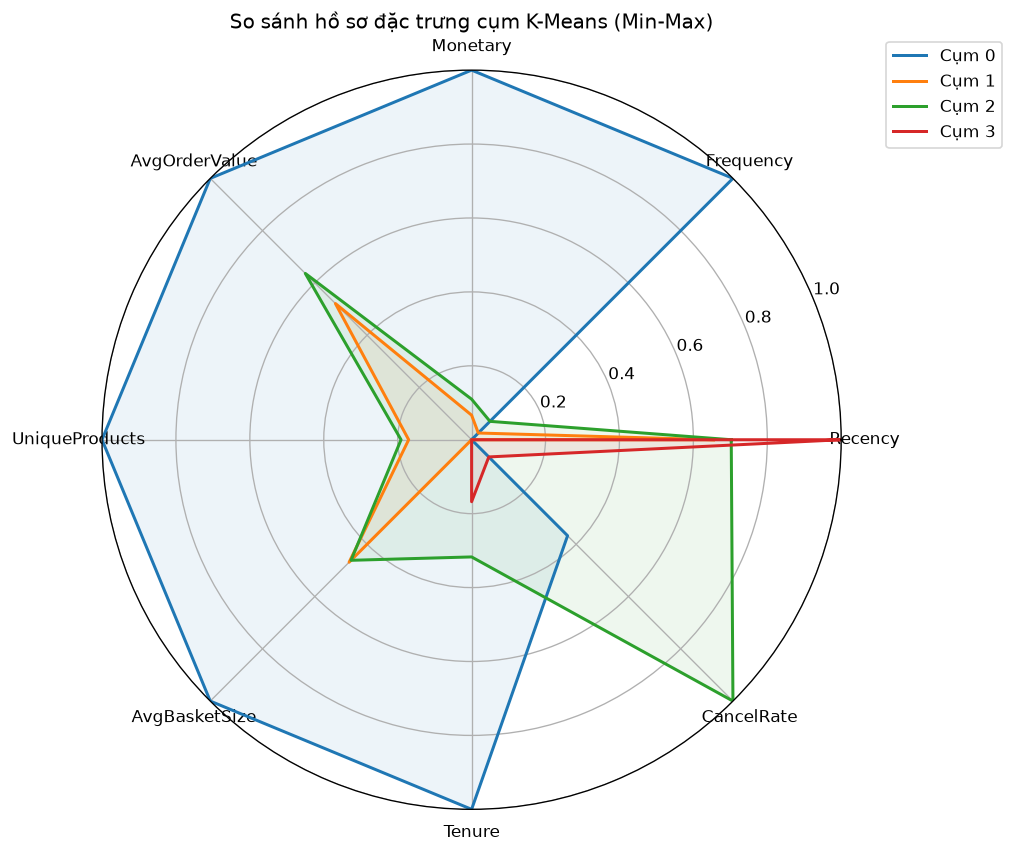

In [4]:
feature_min = profile_mean.min(axis=0)
feature_range = profile_mean.max(axis=0) - feature_min
normalized_mean = (profile_mean - feature_min).div(feature_range.replace(0, 1), axis=1)
normalized_mean.to_csv(RESULTS_DIR / "cluster_profile_radar_minmax.csv", index_label="kmeans")

angles = np.linspace(0, 2 * np.pi, len(FEATURES), endpoint=False).tolist()
angles += angles[:1]
fig, ax = plt.subplots(figsize=(9, 8), subplot_kw={"polar": True})
for cluster_id, values in normalized_mean.iterrows():
    scores = values.tolist()
    scores += scores[:1]
    ax.plot(angles, scores, linewidth=1.8, label=f"Cụm {cluster_id}")
    ax.fill(angles, scores, alpha=0.08)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(FEATURES)
ax.set_ylim(0, 1)
ax.set_title("So sánh hồ sơ đặc trưng cụm K-Means (Min-Max)")
ax.legend(loc="upper left", bbox_to_anchor=(1.05, 1.05))
fig.savefig(FIGURES_DIR / "cluster_radar.png", dpi=200, bbox_inches="tight")
plt.show()


## 4. Boxplot theo cụm

Mỗi biểu đồ thể hiện phân bố một đặc trưng theo cụm; ẩn điểm ngoại lai để dễ đọc. Các đặc trưng không âm được hiển thị trên trục log nhằm giảm ảnh hưởng của lệch phải; `CancelRate` giữ thang tuyến tính.

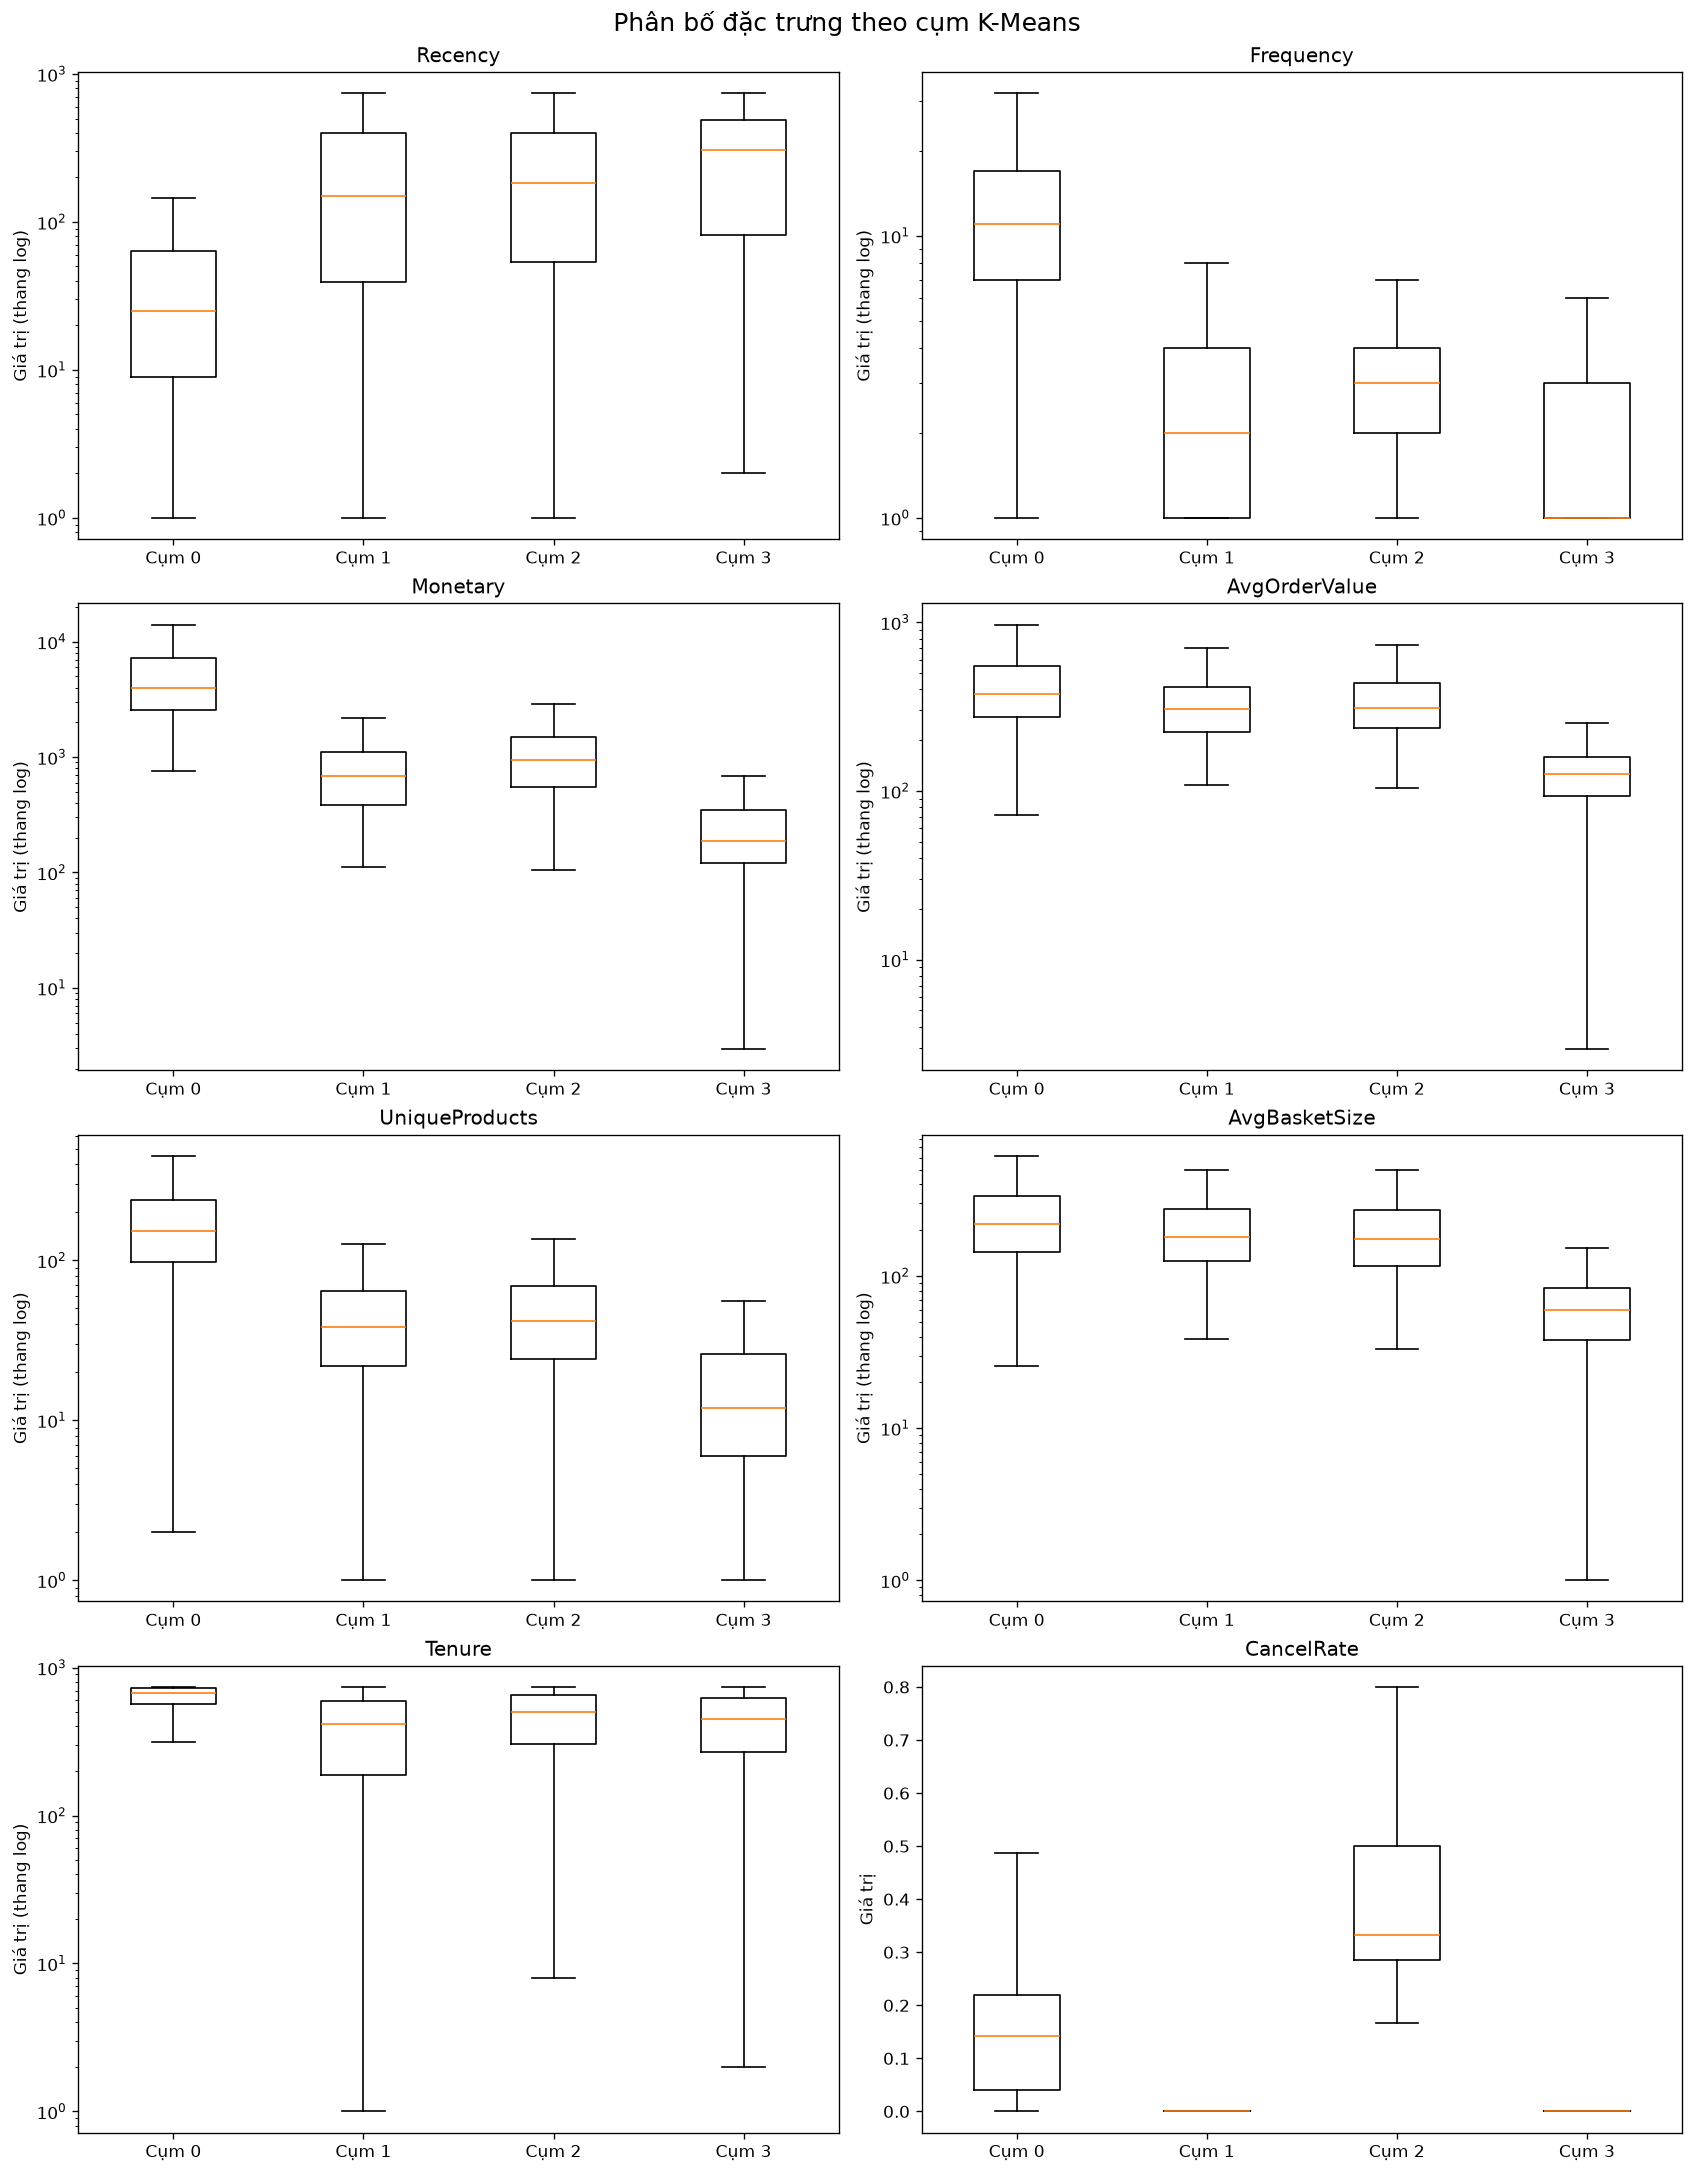

In [5]:
cluster_ids = sorted(data["kmeans"].unique())
fig, axes = plt.subplots(4, 2, figsize=(14, 18), constrained_layout=True)

for ax, feature in zip(axes.flat, FEATURES):
    values = [
        data.loc[data["kmeans"] == cluster_id, feature].dropna().to_numpy()
        for cluster_id in cluster_ids
    ]
    ax.boxplot(values, showfliers=False)
    ax.set_xticks(range(1, len(cluster_ids) + 1))
    ax.set_xticklabels([f"Cụm {cluster_id}" for cluster_id in cluster_ids])
    ax.set_title(feature)
    ax.set_ylabel("Giá trị")
    if feature != "CancelRate" and all(np.all(group > 0) for group in values):
        ax.set_yscale("log")
        ax.set_ylabel("Giá trị (thang log)")

fig.suptitle("Phân bố đặc trưng theo cụm K-Means", fontsize=15)
fig.savefig(FIGURES_DIR / "cluster_boxplots.png", dpi=200, bbox_inches="tight")
plt.show()


## 5. Phân tích điểm nhiễu DBSCAN

So sánh khách DBSCAN gán nhãn `-1` với khách không nhiễu. Tỷ lệ khách thuộc 5% cao nhất của toàn tập giúp kiểm tra liệu nhiễu có tập trung vào khách chi tiêu/đơn hàng đặc biệt lớn hay không. Đây là mô tả ngoại biên theo đặc trưng, không khẳng định nguyên nhân kinh doanh.

In [6]:
noise = data.loc[data["dbscan"] == -1]
non_noise = data.loc[data["dbscan"] != -1]
if noise.empty or non_noise.empty:
    raise ValueError("Cần có cả điểm nhiễu và điểm không nhiễu để so sánh DBSCAN.")

noise_profile = pd.DataFrame({
    "noise": noise[FEATURES].median(),
    "non_noise": non_noise[FEATURES].median(),
    "whole_population": data[FEATURES].median(),
})
noise_profile["noise_to_non_noise_median_ratio"] = (
    noise_profile["noise"] / noise_profile["non_noise"].replace(0, np.nan)
)
noise_profile.to_csv(RESULTS_DIR / "dbscan_noise_profile.csv", index_label="feature")

tail_rows = []
for feature in ["Monetary", "AvgOrderValue", "AvgBasketSize", "UniqueProducts"]:
    threshold = data[feature].quantile(0.95)
    tail_rows.append({
        "feature": feature,
        "whole_population_p95": threshold,
        "noise_share_at_or_above_p95": float((noise[feature] >= threshold).mean()),
        "non_noise_share_at_or_above_p95": float((non_noise[feature] >= threshold).mean()),
    })
tail_comparison = pd.DataFrame(tail_rows)
tail_comparison.to_csv(RESULTS_DIR / "dbscan_noise_tail_comparison.csv", index=False)

noise_summary = pd.DataFrame([
    {"group": "DBSCAN noise (-1)", "customers": len(noise), "customer_share": len(noise) / len(data),
     "revenue_sum": noise["Monetary"].sum(), "recency_median": noise["Recency"].median(),
     "frequency_median": noise["Frequency"].median(), "monetary_median": noise["Monetary"].median(),
     "avg_order_value_median": noise["AvgOrderValue"].median(), "cancel_rate_median": noise["CancelRate"].median()},
    {"group": "Non-noise", "customers": len(non_noise), "customer_share": len(non_noise) / len(data),
     "revenue_sum": non_noise["Monetary"].sum(), "recency_median": non_noise["Recency"].median(),
     "frequency_median": non_noise["Frequency"].median(), "monetary_median": non_noise["Monetary"].median(),
     "avg_order_value_median": non_noise["AvgOrderValue"].median(), "cancel_rate_median": non_noise["CancelRate"].median()},
])
noise_summary.to_csv(RESULTS_DIR / "dbscan_noise_summary.csv", index=False)

display(noise_summary.round(4))
display(noise_profile.round(2))
display(tail_comparison.round(4))


,group,customers,customer_share,revenue_sum,recency_median,frequency_median,monetary_median,avg_order_value_median,cancel_rate_median
0,DBSCAN noise (-1),345,0.059,5975825.32,74.0,3.0,1927.30,441.1750,0.0949
1,Non-noise,5507,0.941,11092757.40,97.0,3.0,834.44,275.4389,0.0000


,noise,non_noise,whole_population,noise_to_non_noise_median_ratio
Recency,74.00,97.00,96.00,0.76
Frequency,3.00,3.00,3.00,1.00
Monetary,1927.30,834.44,856.02,2.31
AvgOrderValue,441.18,275.44,277.87,1.60
UniqueProducts,13.00,46.00,45.00,0.28
AvgBasketSize,290.31,153.67,155.00,1.89
Tenure,535.00,530.00,530.00,1.01
CancelRate,0.09,0.00,0.00,NaN


,feature,whole_population_p95,noise_share_at_or_above_p95,non_noise_share_at_or_above_p95
0,Monetary,9270.2705,0.2551,0.0372
1,AvgOrderValue,871.2067,0.3710,0.0300
2,AvgBasketSize,551.0000,0.3971,0.0285
3,UniqueProducts,281.0000,0.0899,0.0478


### Nhận xét và cách xử lý

Đọc bảng trên để kết luận dựa trên số liệu thực tế. Nếu nhóm nhiễu tập trung vào Monetary hoặc AvgOrderValue cao hơn rõ rệt, không nên tự động gộp vào cụm thường: giữ thành nhóm ngoại biên để kiểm tra khách sỉ/đơn bất thường và xây dựng chính sách riêng. Nếu không có chênh lệch rõ, cần xem từng trường hợp và kiểm tra dữ liệu trước khi quyết định gộp. Nhóm nhiễu của DBSCAN không phải là persona K-Means.